In [ ]:
import numpy as np
import skimage as ski

# Nearest Neighbor Image Interplolation

/tmp/ipython-input-534/1073581205.py:2: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  ski.io.imshow(image)


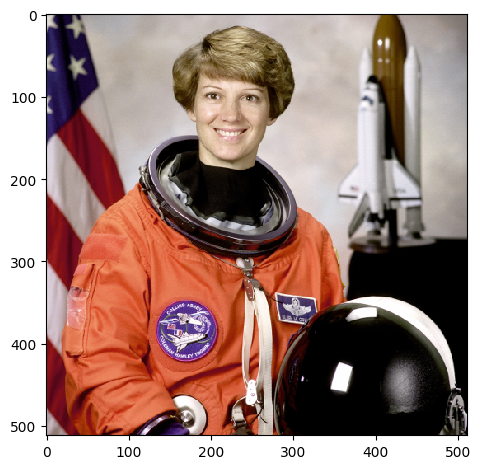

In [ ]:
image = ski.data.astronaut()
ski.io.imshow(image)

In [ ]:
image.shape

(512, 512, 3)

In [ ]:
scaledImageCanva = np.zeros((512,1024,3),dtype=np.uint8)
for i in range(image.shape[0]):
  for j in range(image.shape[1]):
    scaledImageCanva[i, j*2:(j*2)+2] = image[i,j]

/tmp/ipython-input-534/1539972023.py:1: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  ski.io.imshow(scaledImageCanva)


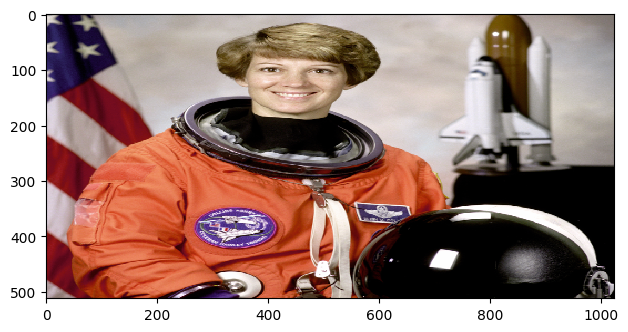

In [ ]:
ski.io.imshow(scaledImageCanva)

In [ ]:
def nearest_neighbor_upscale(image, width_scale, height_scale):
  scaledImageCanva = np.zeros((image.shape[0]*height_scale,image.shape[1]*width_scale,image.shape[2]),dtype=np.uint8)
  for i in range(image.shape[0]):
    for j in range(image.shape[1]):
      scaledImageCanva[i*height_scale:(i*height_scale)+height_scale, j*width_scale:(j*width_scale)+width_scale] = image[i,j]
  return scaledImageCanva
#------------------------------------------------------------------------------------------------------------------------------------#
width_scale = 3
height_scale = 3
scaledImage = nearest_neighbor_upscale(image,width_scale,height_scale)

In [ ]:
scaledImage.shape

(1536, 1536, 3)

/tmp/ipython-input-534/1539972023.py:1: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  ski.io.imshow(scaledImageCanva)


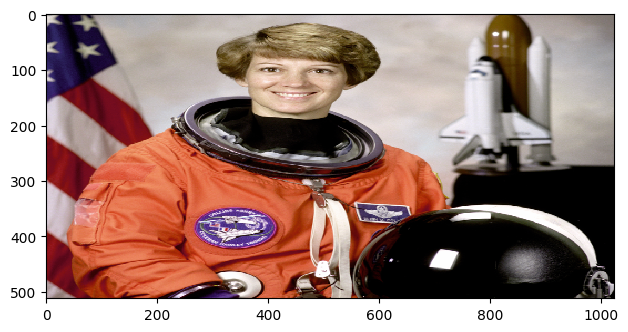

In [ ]:
ski.io.imshow(scaledImageCanva)

## Zooming (NNeighbor)

/tmp/ipython-input-534/1013318527.py:3: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  ski.io.imshow(zoomed_image)


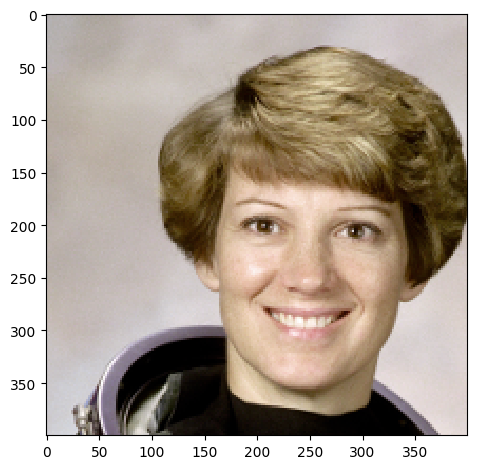

In [ ]:
croped_section = image[0:200, 100:300]
zoomed_image = nearest_neighbor_upscale(croped_section, 2, 2)
ski.io.imshow(zoomed_image)

# Image Interploation (Shrinking)

In [ ]:
512/2

256.0

/tmp/ipython-input-3088060316.py:1: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  ski.io.imshow(shrinkedIamge)


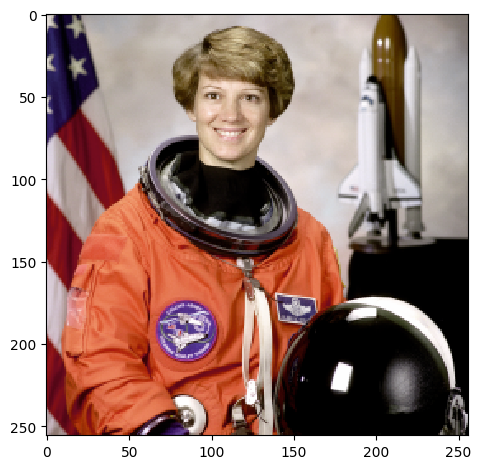

In [ ]:
ski.io.imshow(image)

In [ ]:
shrinked = np.zeros((256,256,3),dtype=np.uint8)
for i in range(shrinked.shape[0]):
  for j in range(shrinked.shape[1]):
    for k in range(shrinked.shape[2]):
      tempArray = image[i*2:(i*2)+2,j*2:(j*2)+2,k]
      shrinked[i,j,k] = tempArray.mean()

/tmp/ipython-input-2847572343.py:1: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  ski.io.imshow(shrinked)


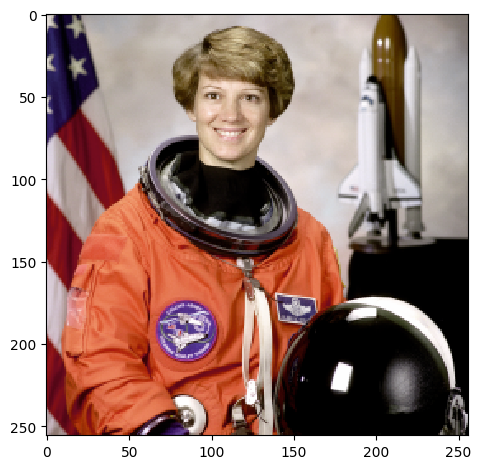

In [ ]:
ski.io.imshow(shrinked)

# BL interpolation

In [ ]:
def bilinear_interpolation(x, y, points):
    '''Interpolate (x,y) from values associated with four points.

    The four points are a list of four triplets:  (x, y, value).
    The x, y values must be in ascending order.
    '''
    points = sorted(points)               # order points by x, then by y
    (x1, y1, q11), (_x1, y2, q12), (x2, _y1, q21), (_x2, _y2, q22) = points

    if x1 != _x1 or x2 != _x2 or y1 != _y1 or y2 != _y2:
        raise ValueError('points do not form a rectangle')
    if not x1 <= x <= x2 or not y1 <= y <= y2:
        raise ValueError('(x, y) not within the rectangle')

    return (q11 * (x2 - x) * (y2 - y) +
            q21 * (x - x1) * (y2 - y) +
            q12 * (x2 - x) * (y - y1) +
            q22 * (x - x1) * (y - y1)
           ) / ((x2 - x1) * (y2 - y1) + 0.0)

# Test
points = [(1, 1, 1), (1, 2, 2), (2, 1, 3), (2, 2, 4)]
print(bilinear_interpolation(1.5, 1.5, points))  # 2.5

2.5


In [ ]:
def bilinear_interpolation(image, new_width, new_height):

    height, width, channels = image.shape

    resized_image = np.zeros((new_height, new_width, channels), dtype=np.uint8)

    x_scale = width / new_width
    y_scale = height / new_height

    for i in range(new_height):
        for j in range(new_width):
            x = j * x_scale
            y = i * y_scale

            x1 = int(x)
            x2 = min(x1 + 1, width - 1)
            y1 = int(y)
            y2 = min(y1 + 1, height - 1)

            x_weight = x - x1
            y_weight = y - y1

            a = image[y1, x1]
            b = image[y1, x2]
            c = image[y2, x1]
            d = image[y2, x2]

            resized_image[i, j] = (
                a * (1 - x_weight) * (1 - y_weight) +
                b * x_weight * (1 - y_weight) +
                c * (1 - x_weight) * y_weight +
                d * x_weight * y_weight
            )

    return resized_image


/tmp/ipython-input-1073581205.py:2: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  ski.io.imshow(image)


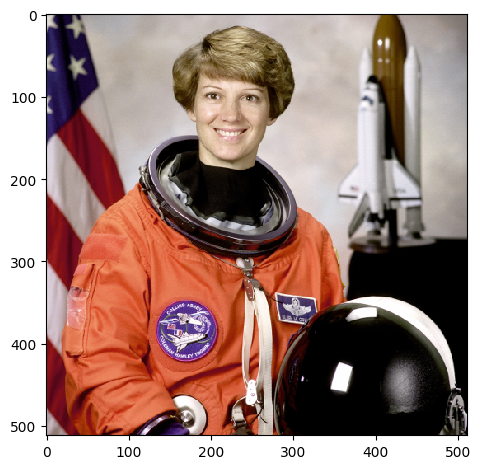

In [ ]:
image = ski.data.astronaut()
ski.io.imshow(image)

array([[[154, 147, 151],
        [109, 103, 124],
        [ 63,  58, 102],
        ...,
        [127, 120, 115],
        [120, 117, 106],
        [125, 119, 110]],

       [[177, 171, 171],
        [144, 141, 143],
        [113, 114, 124],
        ...,
        [127, 118, 112],
        [124, 115, 108],
        [121, 116, 105]],

       [[201, 194, 193],
        [182, 178, 175],
        [168, 165, 164],
        ...,
        [128, 120, 117],
        [126, 116, 112],
        [124, 114, 109]],

       ...,

       [[186, 170, 176],
        [186, 170, 177],
        [183, 168, 170],
        ...,
        [  0,   0,   0],
        [  0,   0,   1],
        [  0,   0,   0]],

       [[183, 169, 170],
        [182, 167, 171],
        [185, 164, 176],
        ...,
        [  0,   0,   1],
        [  1,   1,   1],
        [  0,   0,   0]],

       [[184, 167, 172],
        [183, 165, 169],
        [180, 162, 171],
        ...,
        [  0,   0,   0],
        [  1,   1,   1],
        [  0,   0,   0]]], dtype=uint8)
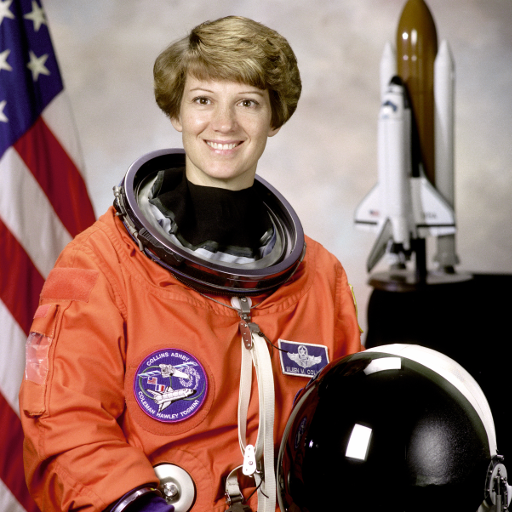

In [ ]:
image

/tmp/ipython-input-1069538620.py:6: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  ski.io.imshow(resized_image)


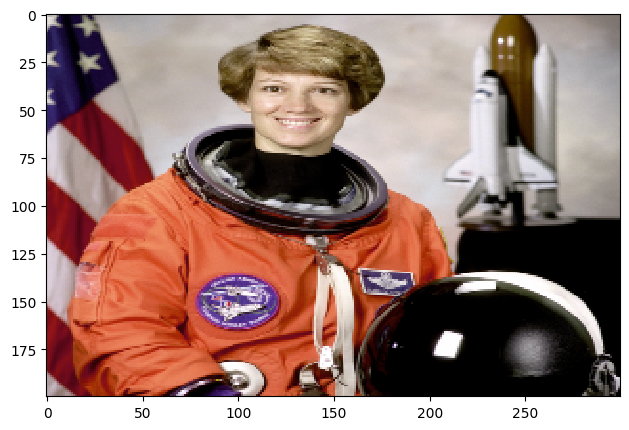

In [ ]:
new_width = 300
new_height = 200

# Resize the image using bilinear interpolation
resized_image = bilinear_interpolation(image, new_width, new_height)
ski.io.imshow(resized_image)